In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("/content/train.csv")

In [3]:
df.head(9)

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1
5,5,28.0,7.37,1.78,1.56,3.38,8.33,210.0,40.0,7.85,Male,High,No,0
6,6,18.0,4.24,1.61,1.14,0.91,5.09,220.0,68.0,7.46,Other,Low,Yes,0
7,7,25.0,10.79,3.92,2.48,3.61,7.20,195.0,NaN,13.45,Other,High,No,1
8,8,26.0,8.42,2.57,3.41,1.90,6.64,99.0,27.0,8.35,Other,Medium,Yes,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 130700 entries, 0 to 130699
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       130700 non-null  int64  
 1   age                      125358 non-null  float64
 2   daily_screen_time_hours  112668 non-null  float64
 3   social_media_hours       105335 non-null  float64
 4   gaming_hours             106497 non-null  float64
 5   work_study_hours         120965 non-null  float64
 6   sleep_hours              122354 non-null  float64
 7   notifications_per_day    117880 non-null  float64
 8   app_opens_per_day        115367 non-null  float64
 9   weekend_screen_time      109510 non-null  float64
 10  gender                   125238 non-null  object 
 11  stress_level             120129 non-null  object 
 12  academic_work_impact     122291 non-null  object 
 13  addicted_label           130699 non-null  float64
dtypes: f

In [4]:
df.isnull().sum()

,0
id,0
age,28929
daily_screen_time_hours,95854
social_media_hours,133995
gaming_hours,126821
work_study_hours,51518
sleep_hours,44480
notifications_per_day,67584
app_opens_per_day,80710
weekend_screen_time,112063


### Visualizing Numerical Column Distributions

Let's start by visualizing the distribution of a numerical column like `age` using a histogram and a box plot to check for outliers and understand its skewness. This will help us determine the best imputation strategy.

In [5]:
# Get numerical columns with missing values
numerical_cols_with_nan = df.select_dtypes(include=np.number).columns[df.select_dtypes(include=np.number).isnull().any()].tolist()

print("Numerical columns with missing values:", numerical_cols_with_nan)

Numerical columns with missing values: ['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time']


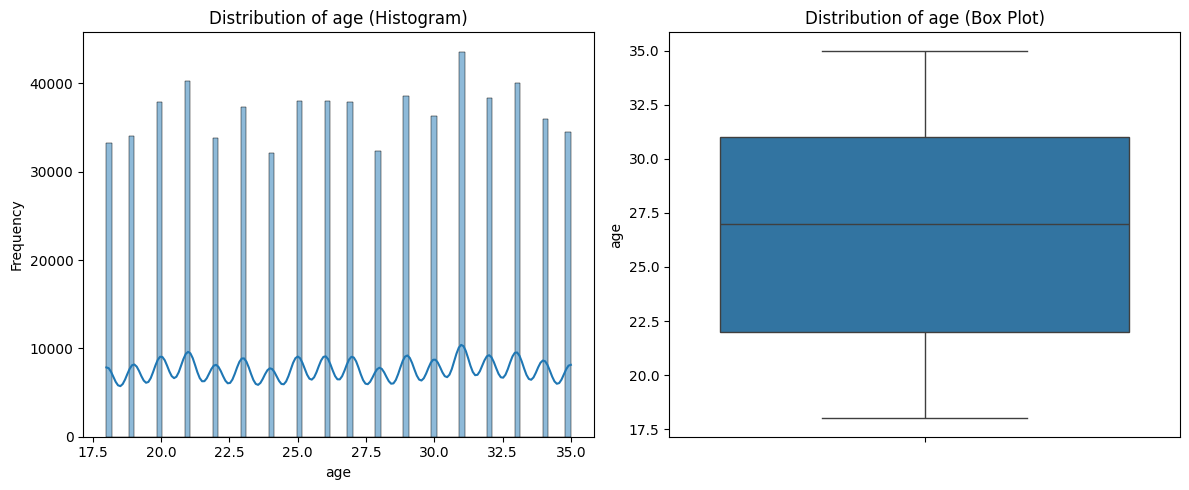

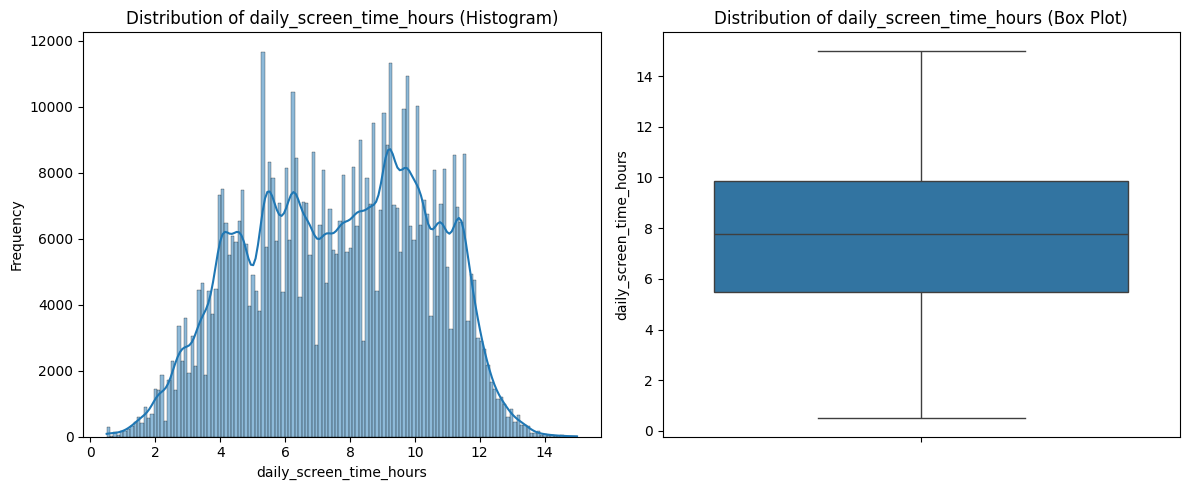

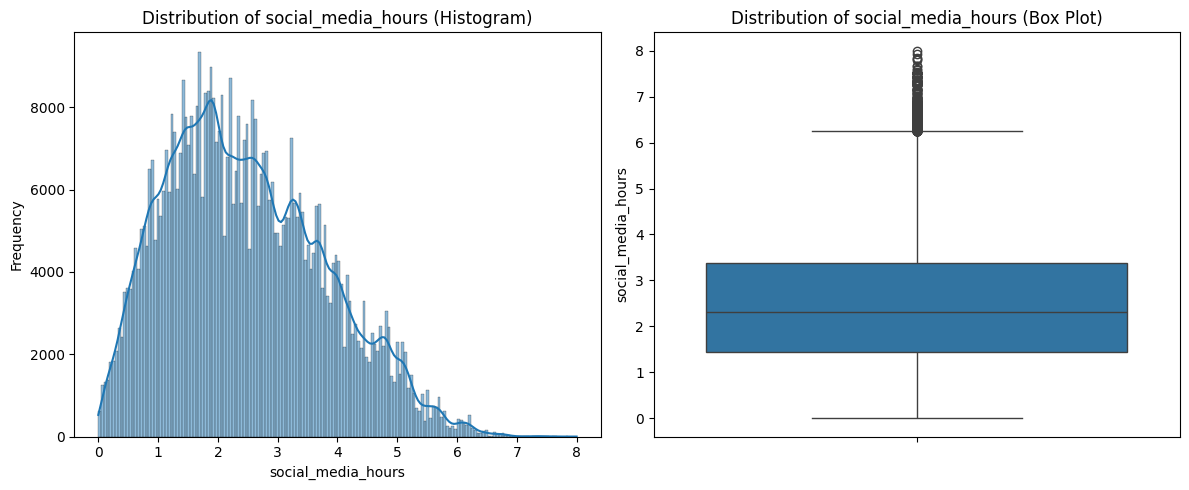

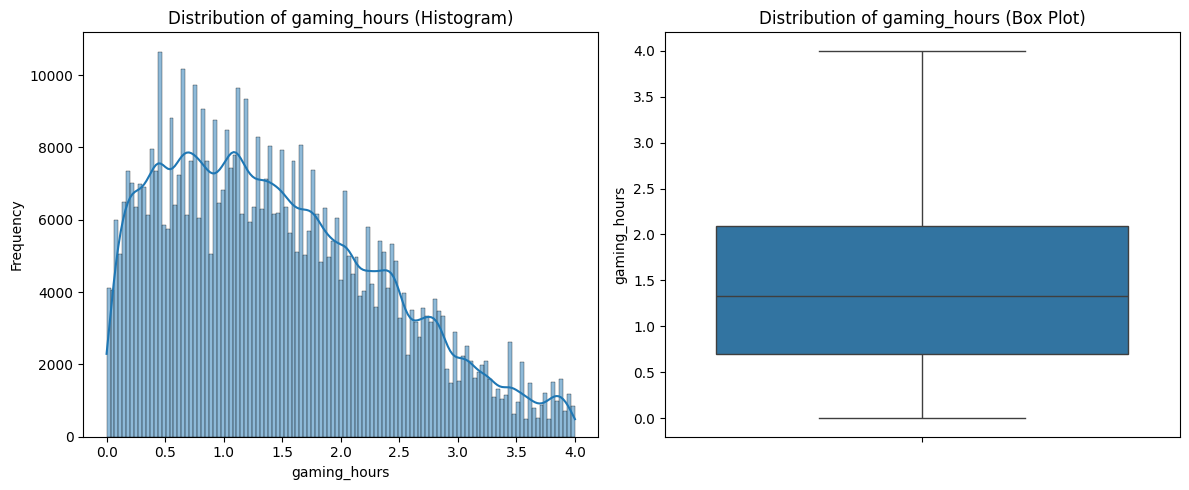

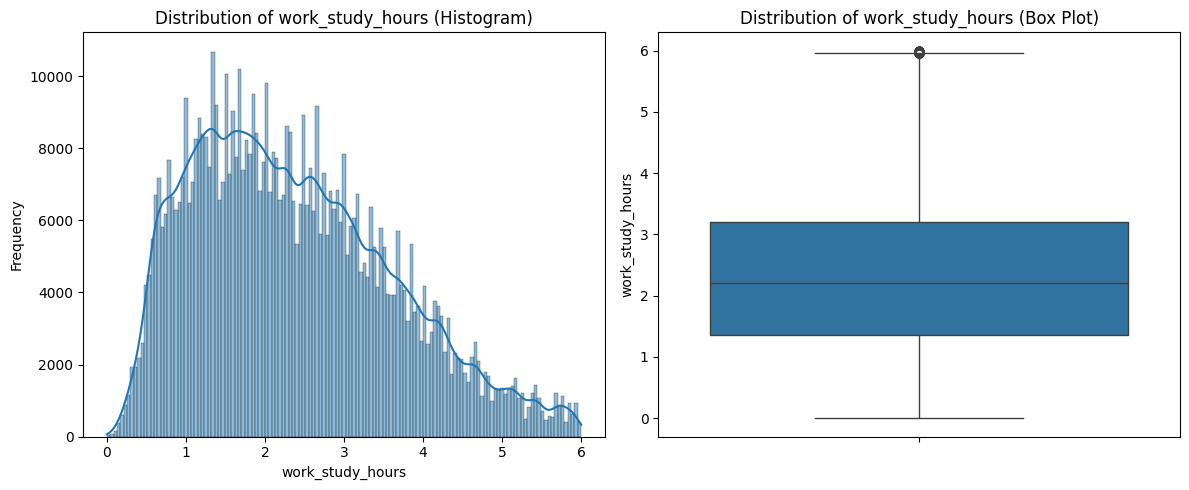

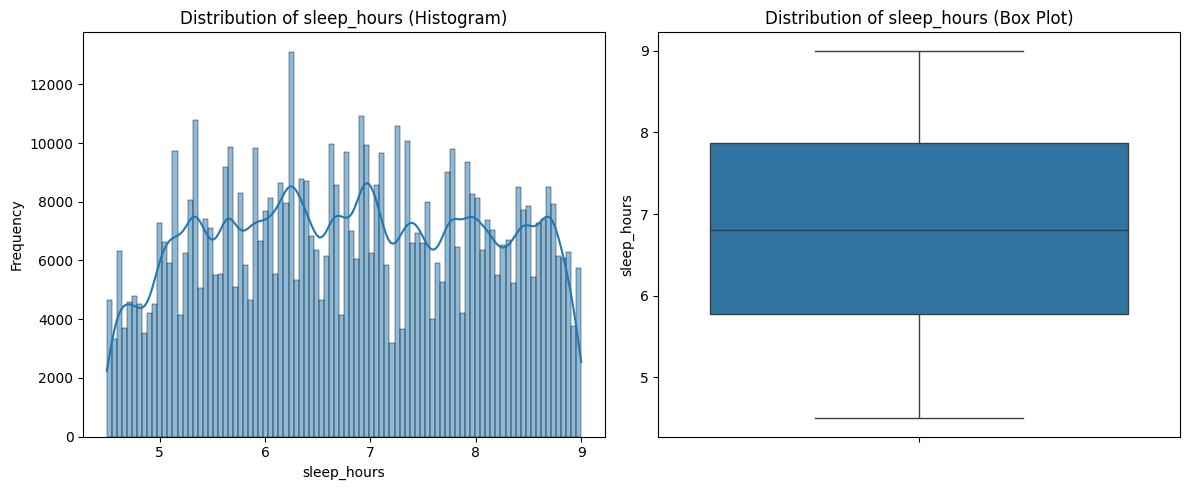

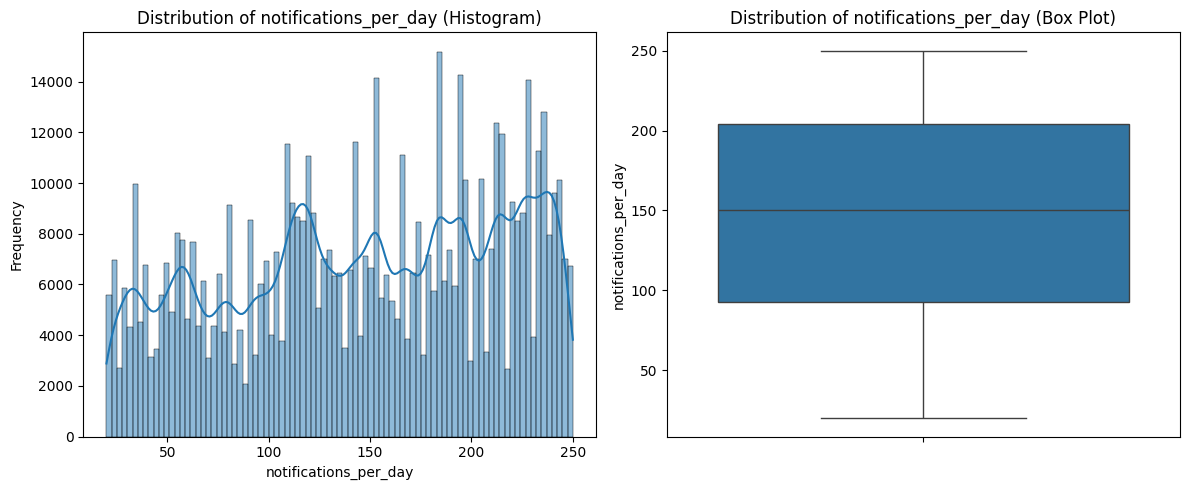

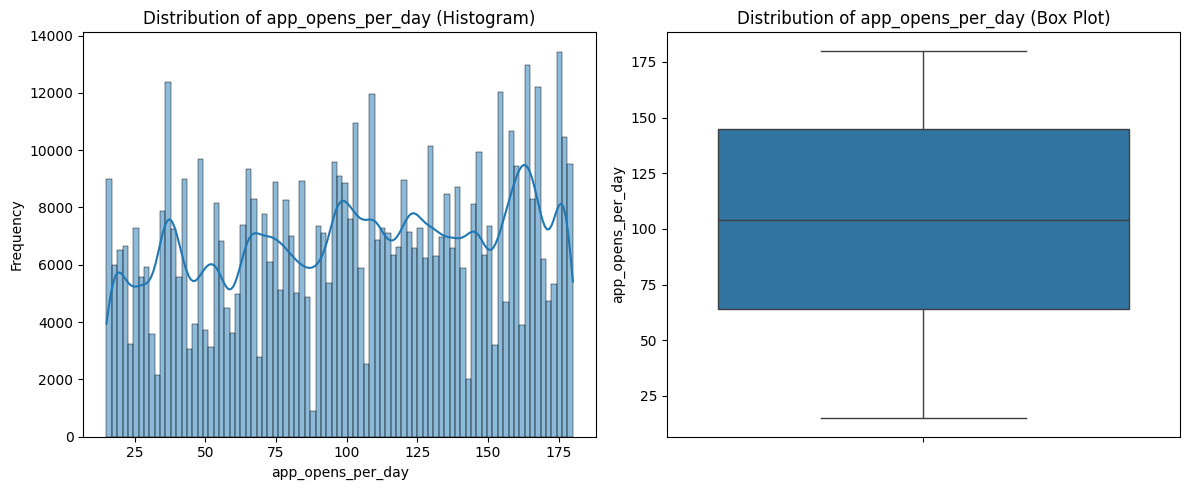

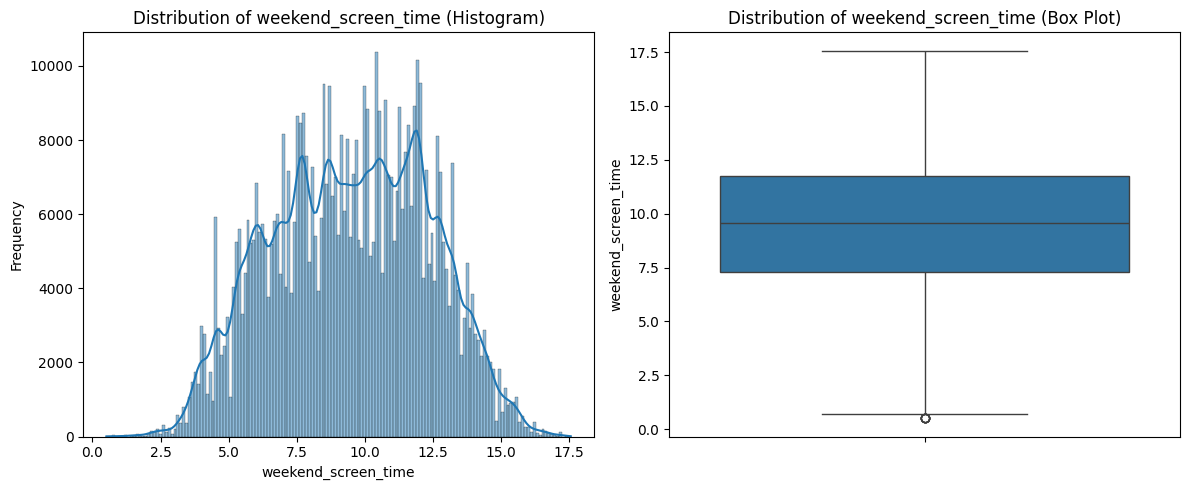

In [6]:
for col in numerical_cols_with_nan:
    plt.figure(figsize=(12, 5))

    # Histogram
    plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f'Distribution of {col} (Histogram)')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    # Box plot
    plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
    sns.boxplot(y=df[col].dropna())
    plt.title(f'Distribution of {col} (Box Plot)')
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

### Imputing Missing Numerical Values

Based on our analysis:
- `age`: will be imputed with the **mean** due to its relatively uniform distribution.
- All other numerical columns with missing values (`daily_screen_time_hours`, `social_media_hours`, `gaming_hours`, `work_study_hours`, `sleep_hours`, `notifications_per_day`, `app_opens_per_day`, `weekend_screen_time`) will be imputed with their respective **medians** due to skewness and the presence of outliers.

In [7]:
# Impute 'age' with the mean
df['age'].fillna(df['age'].mean(), inplace=True)

# Impute other numerical columns with the median
median_impute_cols = [col for col in numerical_cols_with_nan if col != 'age']
for col in median_impute_cols:
    df[col].fillna(df[col].median(), inplace=True)

print("Numerical columns imputation complete.")

Numerical columns imputation complete.


### Verifying Missing Values After Imputation

In [8]:
df[numerical_cols_with_nan].isnull().sum()

,0
age,0
daily_screen_time_hours,0
social_media_hours,0
gaming_hours,0
work_study_hours,0
sleep_hours,0
notifications_per_day,0
app_opens_per_day,0
weekend_screen_time,0


### Imputing Missing Categorical Values

For categorical columns, we will impute missing values with the **mode**.

In [9]:
# Get categorical columns with missing values
categorical_cols_with_nan = df.select_dtypes(include='object').columns[df.select_dtypes(include='object').isnull().any()].tolist()

print("Categorical columns with missing values:", categorical_cols_with_nan)

# Impute categorical columns with the mode
for col in categorical_cols_with_nan:
    df[col].fillna(df[col].mode()[0], inplace=True)

print("Categorical columns imputation complete.")

Categorical columns with missing values: ['gender', 'stress_level', 'academic_work_impact']
Categorical columns imputation complete.


### Final Verification of All Missing Values

In [10]:
df.isnull().sum()

,0
id,0
age,0
daily_screen_time_hours,0
social_media_hours,0
gaming_hours,0
work_study_hours,0
sleep_hours,0
notifications_per_day,0
app_opens_per_day,0
weekend_screen_time,0


In [ ]:
df

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,7.77,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1.0
1,1,19.0,5.97,1.08,1.34,3.03,8.22,76.0,19.0,9.56,Female,Medium,No,0.0
2,2,18.0,5.09,2.30,1.34,2.20,6.25,134.0,60.0,7.47,Female,Low,Yes,0.0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,Yes,1.0
4,4,26.0,11.20,1.87,2.81,1.95,5.25,150.0,104.0,13.39,Female,Medium,No,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
130695,130695,26.0,7.77,3.39,1.34,2.20,7.82,24.0,93.0,9.56,Male,Low,Yes,1.0
130696,130696,28.0,3.38,1.44,1.34,1.13,6.30,227.0,127.0,6.95,Other,Medium,Yes,1.0
130697,130697,22.0,1.71,2.30,1.34,0.27,7.54,165.0,104.0,6.18,Female,High,No,0.0
130698,130698,21.0,8.04,3.75,2.26,1.29,6.44,94.0,108.0,9.12,Male,Low,Yes,1.0


In [11]:
df.loc[df['academic_work_impact'] == 'No' , 'academic_work_impact'] = False
df.loc[df['academic_work_impact'] == 'Yes' , 'academic_work_impact'] = True

In [ ]:
df

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.000000,7.76,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,False,1.0
1,1,19.000000,5.97,1.08,1.34,3.03,8.22,76.0,19.0,9.55,Female,Medium,False,0.0
2,2,18.000000,5.09,2.29,1.34,2.20,6.25,134.0,60.0,7.47,Female,Low,True,0.0
3,3,21.000000,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,True,1.0
4,4,26.000000,11.20,1.87,2.81,1.95,5.25,150.0,105.0,13.39,Female,Medium,False,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98431,98431,21.000000,4.71,1.67,0.75,1.66,6.25,150.0,138.0,3.92,Female,High,True,0.0
98432,98432,31.000000,7.76,3.04,2.37,4.20,8.55,232.0,167.0,15.53,Male,Low,True,1.0
98433,98433,20.000000,7.76,2.29,1.34,2.20,6.81,150.0,105.0,8.71,Male,High,True,1.0
98434,98434,26.000000,7.76,2.29,1.57,1.05,7.46,132.0,109.0,7.81,Male,Medium,False,0.0


In [12]:
df['academic_work_impact'] = df['academic_work_impact'].astype(int)

In [13]:
df.loc[df['stress_level'] == 'Low' , 'stress_level'] = 0
df.loc[df['stress_level'] == 'Medium' , 'stress_level'] = 1
df.loc[df['stress_level'] == 'High' , 'stress_level'] = 2

In [14]:
df.loc[df['gender'] == 'Male' , 'gender'] = 1
df.loc[df['gender'] == 'Female' , 'gender'] = 0
df.loc[df['gender'] == 'Other' , 'gender'] = 2

In [15]:
df

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.000000,7.77,1.83,1.59,2.11,7.46,122.0,38.0,8.63,1,1,0,1
1,1,19.000000,5.97,1.08,1.33,3.03,8.22,76.0,19.0,9.58,0,1,0,0
2,2,18.000000,5.09,2.31,1.33,2.20,6.25,134.0,60.0,7.47,0,0,1,0
3,3,21.000000,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,2,0,1,1
4,4,26.000000,11.20,1.87,2.81,1.95,5.25,150.0,104.0,13.39,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
691364,691364,22.000000,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,1,2,0,1
691365,691365,20.000000,3.45,1.86,0.89,0.30,6.59,221.0,42.0,8.47,0,2,0,1
691366,691366,26.615408,7.77,2.31,1.33,2.06,6.16,150.0,86.0,7.79,2,1,0,1
691367,691367,22.000000,11.78,3.69,0.23,1.35,5.53,171.0,62.0,7.71,2,2,1,1


In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [17]:
df['age'] = scaler.fit_transform(df[['age']])
df['daily_screen_time_hours'] = scaler.fit_transform(df[['daily_screen_time_hours']])
df['social_media_hours'] = scaler.fit_transform(df[['social_media_hours']])
df['gaming_hours'] = scaler.fit_transform(df[['gaming_hours']])
df['work_study_hours'] = scaler.fit_transform(df[['work_study_hours']])
df['sleep_hours'] = scaler.fit_transform(df[['sleep_hours']])
df['notifications_per_day'] = scaler.fit_transform(df[['notifications_per_day']])
df['app_opens_per_day'] = scaler.fit_transform(df[['app_opens_per_day']])
df['weekend_screen_time'] = scaler.fit_transform(df[['weekend_screen_time']])

In [ ]:
df

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,-5.234493e-01,0.047336,-0.505450,0.173843,-0.201477,0.545243,-0.387990,-1.433338,-0.325031,1,1,0,1.0
1,1,-1.516154e+00,-0.665046,-1.139876,-0.121099,0.557004,1.182898,-1.122942,-1.853369,0.030523,0,1,0,0.0
2,2,-1.714695e+00,-1.013322,-0.107876,-0.121099,-0.135522,-0.469971,-0.196263,-0.946987,-0.768518,0,0,1,0.0
3,3,-1.119072e+00,-0.486951,-0.987613,-0.026717,0.829068,1.711480,-0.547762,-0.195354,-0.313562,2,0,1,1.0
4,4,-1.263673e-01,1.404819,-0.471614,1.613156,-0.333387,-1.308991,0.059372,0.025715,1.494795,0,1,0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114583,114583,-3.249083e-01,-1.448666,-1.579744,-0.852553,-0.184989,0.452951,0.059372,-1.698621,-1.456688,2,1,1,0.0
114584,114584,-1.317613e+00,0.047336,-0.107876,-0.274468,-0.135522,-0.000120,1.065938,0.489959,0.095517,0,1,1,1.0
114585,114585,7.217373e-02,-1.646550,-1.055286,-0.616600,-0.935226,1.350702,1.177778,-0.792239,-1.345816,1,1,0,0.0
114586,114586,-9.205313e-01,-0.506739,-1.681252,0.103057,1.076399,-0.855920,-0.228218,0.644707,-0.191221,0,0,0,0.0


In [18]:
x = df.drop(['addicted_label' , 'id'], axis=1)
y = df['addicted_label']

In [ ]:
x

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact
0,-5.234496e-01,0.044430,-0.500367,0.173779,-0.203263,0.543951,-0.389017,-1.437736,-0.324569,1,1,0
1,-1.515442e+00,-0.663757,-1.135089,-0.121175,0.553504,1.181081,-1.124164,-1.857839,0.027307,0,1,0
2,-1.713841e+00,-1.011916,-0.111070,-0.121175,-0.129231,-0.470427,-0.197239,-0.951300,-0.768238,0,0,1
3,-1.118645e+00,-0.485721,-0.982756,-0.026790,0.824953,1.709228,-0.548831,-0.199537,-0.313095,2,0,1
4,-1.266525e-01,1.405414,-0.466515,1.613153,-0.334874,-1.308756,0.058465,0.043680,1.496004,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
98431,-1.118645e+00,-1.162257,-0.635774,-0.817266,-0.573420,-0.470427,0.058465,0.773333,-2.126018,0,2,1
98432,8.653402e-01,0.044430,0.523653,1.094035,1.515915,1.457730,1.368946,1.414543,2.314497,1,0,1
98433,-1.317044e+00,0.044430,-0.111070,-0.121175,-0.129231,-0.000963,0.058465,0.043680,-0.293971,1,2,1
98434,-1.266525e-01,0.044430,-0.111070,0.150183,-1.075190,0.543951,-0.229202,0.132123,-0.638197,1,1,0


In [19]:
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size=0.2 , random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
tree = DecisionTreeClassifier()

In [ ]:
tree.fit(x_train , y_train)

DecisionTreeClassifier()

In [ ]:
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report

In [ ]:
tree_pred = tree.predict(x_test)

In [ ]:
print(accuracy_score(y_test , tree_pred))
print(confusion_matrix(y_test , tree_pred))
print(classification_report(y_test , tree_pred))

0.8139250191277735
[[ 5249  2385]
 [ 2479 16027]]
              precision    recall  f1-score   support

         0.0       0.68      0.69      0.68      7634
         1.0       0.87      0.87      0.87     18506

    accuracy                           0.81     26140
   macro avg       0.77      0.78      0.78     26140
weighted avg       0.81      0.81      0.81     26140



In [21]:
from sklearn.ensemble import RandomForestClassifier

In [22]:
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, verbose=1, max_depth=20, max_features='sqrt', min_samples_split=2)

In [ ]:
rf.fit(x_train , y_train)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    8.4s


In [ ]:
rf_pred = rf.predict(x_test)

In [ ]:
print(accuracy_score(y_test , rf_pred))
print(confusion_matrix(y_test , rf_pred))
print(classification_report(y_test , rf_pred))

In [20]:
from sklearn.model_selection import RandomizedSearchCV

In [23]:
serch_cv = RandomizedSearchCV(
    (rf) ,
    {
        'n_estimators' : [100, 200, 300, 400],
        'max_features' : ['auto', 'sqrt', 'log2'],
        'max_depth' : [10, 20, 30, 40, 50, 60, None],
        'min_samples_split' : [2, 5, 10],
        'min_samples_leaf' : [1, 2, 4],
        'bootstrap' : [True, False]
    } , cv=5 , n_iter=10 , verbose=2 , random_state=42 , n_jobs=-1
)

In [ ]:
serch_cv.fit(x,y)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   12.4s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:   57.2s
[Parallel(n_jobs=-1)]: Done 300 out of 300 | elapsed:  1.4min finished


RandomizedSearchCV(cv=5,
                   estimator=RandomForestClassifier(max_depth=20,
                                                    n_estimators=200, n_jobs=-1,
                                                    random_state=42,
                                                    verbose=1),
                   n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [10, 20, 30, 40, 50, 60,
                                                      None],
                                        'max_features': ['auto', 'sqrt',
                                                         'log2'],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 200, 300, 400]},
                   random_state=42, verbose=2)

In [ ]:
result = pd.DataFrame(serch_cv.cv_results_)

In [ ]:
serch_cv.best_params_

{'n_estimators': 300,
 'min_samples_split': 2,
 'min_samples_leaf': 2,
 'max_features': 'sqrt',
 'max_depth': 40,
 'bootstrap': False}

In [ ]:
rf_final = RandomForestClassifier(n_estimators=300, min_samples_leaf= 2 , min_samples_split= 2 , max_features= 'sqrt' , max_depth= 40 , bootstrap= False)

In [ ]:
rf_final.fit(x_train , y_train)

RandomForestClassifier(bootstrap=False, max_depth=40, min_samples_leaf=2,
                       n_estimators=300)

In [ ]:
rf_final_pred = rf_final.predict(x_test)

In [ ]:
print(accuracy_score(y_test , rf_final_pred))
print(confusion_matrix(y_test , rf_final_pred))
print(classification_report(y_test , rf_final_pred))

0.8670477354044855
[[ 5045  1672]
 [ 1375 14826]]
              precision    recall  f1-score   support

         0.0       0.79      0.75      0.77      6717
         1.0       0.90      0.92      0.91     16201

    accuracy                           0.87     22918
   macro avg       0.84      0.83      0.84     22918
weighted avg       0.87      0.87      0.87     22918

